In [ ]:
import marimo as mo

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from sklearn.datasets import make_moons

**Actividad 2 · Límites de un perceptrón**

**Nombre:** Carlos Pulido Rosas

# Límites de una sola neurona

En la parte anterior habíamos construido un perceptrón con una función de activación (sigmoide) para resolver un problema de clasificación binaria. Recordamos que la salida del perceptron se calculaba como,

\begin{equation}
A = \sigma (WX + b)
\end{equation}

donde $\sigma (z) = \frac{1}{1+e^{-z}}$ es la función sigmoide.

Normalmente se toma como umbral de decisión cuando A > 0.5, es decir, cuando la $WX + b = 0$. Por lo tanto, **una sola neurona únicamente pude construir una frontera de decision lineal**

In [ ]:
# Definimos algunos widgets con marimo

conjunto = mo.ui.dropdown(
    options={
        "Dos grupos separables": "lineal",
        "Compuerta XOR": "xor",
        "Dos lunas": "lunas",
    },
    value="Compuerta XOR",
    label="Conjunto de datos",
)
ruido = mo.ui.slider(
    start=0.0,
    stop=0.35,
    step=0.01,
    value=0.08,
    label="Ruido",
)
iteraciones = mo.ui.slider(
    start=100,
    stop=5000,
    step=100,
    value=1500,
    label="Iteraciones",
)
learning_rate = mo.ui.slider(
    start=0.01,
    stop=2.0,
    step=0.01,
    value=0.5,
    label="Learning rate",
)

mo.vstack(
    [
        mo.md("### Controles del experimento"),
        conjunto,
        ruido,
        iteraciones,
        learning_rate,
    ]
)

Controles del experimento

In [ ]:
def construir_datos(nombre, ruido, semilla=42):
    """
    Construye un problema de clasificación binaria con observaciones en columnas.
    """
    generador = np.random.default_rng(semilla)

    if nombre == "lineal":
        clase_0 = generador.normal((-1.2, -1.0), ruido + 0.25, (80, 2))
        clase_1 = generador.normal((1.2, 1.0), ruido + 0.25, (80, 2))
        muestras = np.vstack((clase_0, clase_1))
        etiquetas = np.hstack((np.zeros(80), np.ones(80)))
    elif nombre == "xor":
        centros = np.array([[-1, -1], [-1, 1], [1, -1], [1, 1]])
        muestras = np.repeat(centros, 40, axis=0)
        muestras = muestras + generador.normal(0, ruido, muestras.shape)
        etiquetas = np.repeat([0, 1, 1, 0], 40)
    else:
        muestras, etiquetas = make_moons(
            n_samples=200,
            noise=ruido,
            random_state=semilla,
        )

    return muestras.T, etiquetas.reshape(1, -1)

X, y = construir_datos(conjunto.value, ruido.value)

In [ ]:
mo.md(rf"""
## Forma de los datos

Organizamos los datos utilizando la misma convención que en los notebooks anteriores

\[
X\in\mathbb{{R}}^{{n_x\times m}},\qquad
Y\in\mathbb{{R}}^{{1\times m}}
\]

Para el conjunto seleccionado:

- `X.shape = {X.shape}`
- `y.shape = {y.shape}`
- tenemos \(m={X.shape[1]}\) observaciones de entrenamiento.
""")

## Forma de los datos

Organizamos los datos utilizando la misma convención que en los notebooks anteriores

\[
X\in\mathbb{R}^{n_x\times m},\qquad
Y\in\mathbb{R}^{1\times m}
\]

Para el conjunto seleccionado:

- `X.shape = (2, 160)`
- `y.shape = (1, 160)`
- tenemos \(m=160\) observaciones de entrenamiento.

In [ ]:
def sigmoid(Z):
    """
    Aplica la función sigmoide elemento por elemento.
    """
    Z_seguro = np.clip(Z, -500, 500)
    return 1.0 / (1.0 + np.exp(-Z_seguro))

def initialize_parameters(n_x, semilla=42):
    """
    Inicializa los pesos de una única neurona sigmoide.
    """
    generador = np.random.default_rng(semilla)

    W = generador.normal(0, 0.01, (1, n_x))
    b = np.zeros((1, 1))

    parameters = {
        "W":W,
        "b":b
    }

    return parameters

def forward_propagation(X, parameters):
    """
    Calcula Z=WX+b y posteriormente A=sigmoid(Z).
    """
    W = parameters["W"]
    b = parameters["b"]

    Z = np.matmul(W,X) + b

    y_hat = sigmoid(Z)
    
    return y_hat

def loss(y_hat, y):
    """
    Calcula la entropía cruzada binaria promedio.
    """

    A_segura = np.clip(y_hat, 1e-10, 1 - 1e-10)

    loss = -np.mean(y * np.log(A_segura) + (1-y) * np.log(1-A_segura))

    return loss

def backward_propagation(y_hat, X, y):
    """
    Calcula los gradientes de W y b.
    """
    m = X.shape[1]
    dZ = y_hat - y

    dW = np.matmul(dZ,X.T) / m
    db = np.sum(dZ, axis=1, keepdims=True) / m

    grads = {
        "dW": dW,
        "db":db
    }
    return grads

def update_parameters(parameters, grads, learning_rate=0.5):
    """
    Actualiza los parámetros utilizando la regla de descenso del gradiente
    """

    # pesos w y sesgo b
    W = parameters["W"]
    b = parameters["b"]

    # gradiente
    dW = grads["dW"]
    db = grads["db"]

    # descenso del gradiente
    W = W - learning_rate*dW
    b = b - learning_rate*db

    parameters = {
        "W":W,
        "b":b
    }

    return parameters

def nn_model(X, y, iterations=1000, learning_rate=0.5):
    """
    Integra forward, costo, backward y actualización de parámetros.
    """
    parameters = initialize_parameters(X.shape[0])
    costs = []

    # ciclo de entrenamiento
    for i in range(iterations):
        y_hat = forward_propagation(X=X, parameters=parameters)
        error = loss(y_hat=y_hat, y=y)
        grads = backward_propagation(y_hat=y_hat, X=X, y=y)
        parameters = update_parameters(parameters=parameters, grads=grads, learning_rate=learning_rate)

        if i % 10 == 0:
            costs.append((i, error))

    return parameters, costs

In [ ]:
parameters, costs = nn_model(
    X,
    y,
    iterations=iteraciones.value,
    learning_rate=learning_rate.value,
)
probabilities = forward_propagation(X, parameters)
predictions = (probabilities > 0.5).astype(int)
accuracy = float(np.mean(predictions == y))

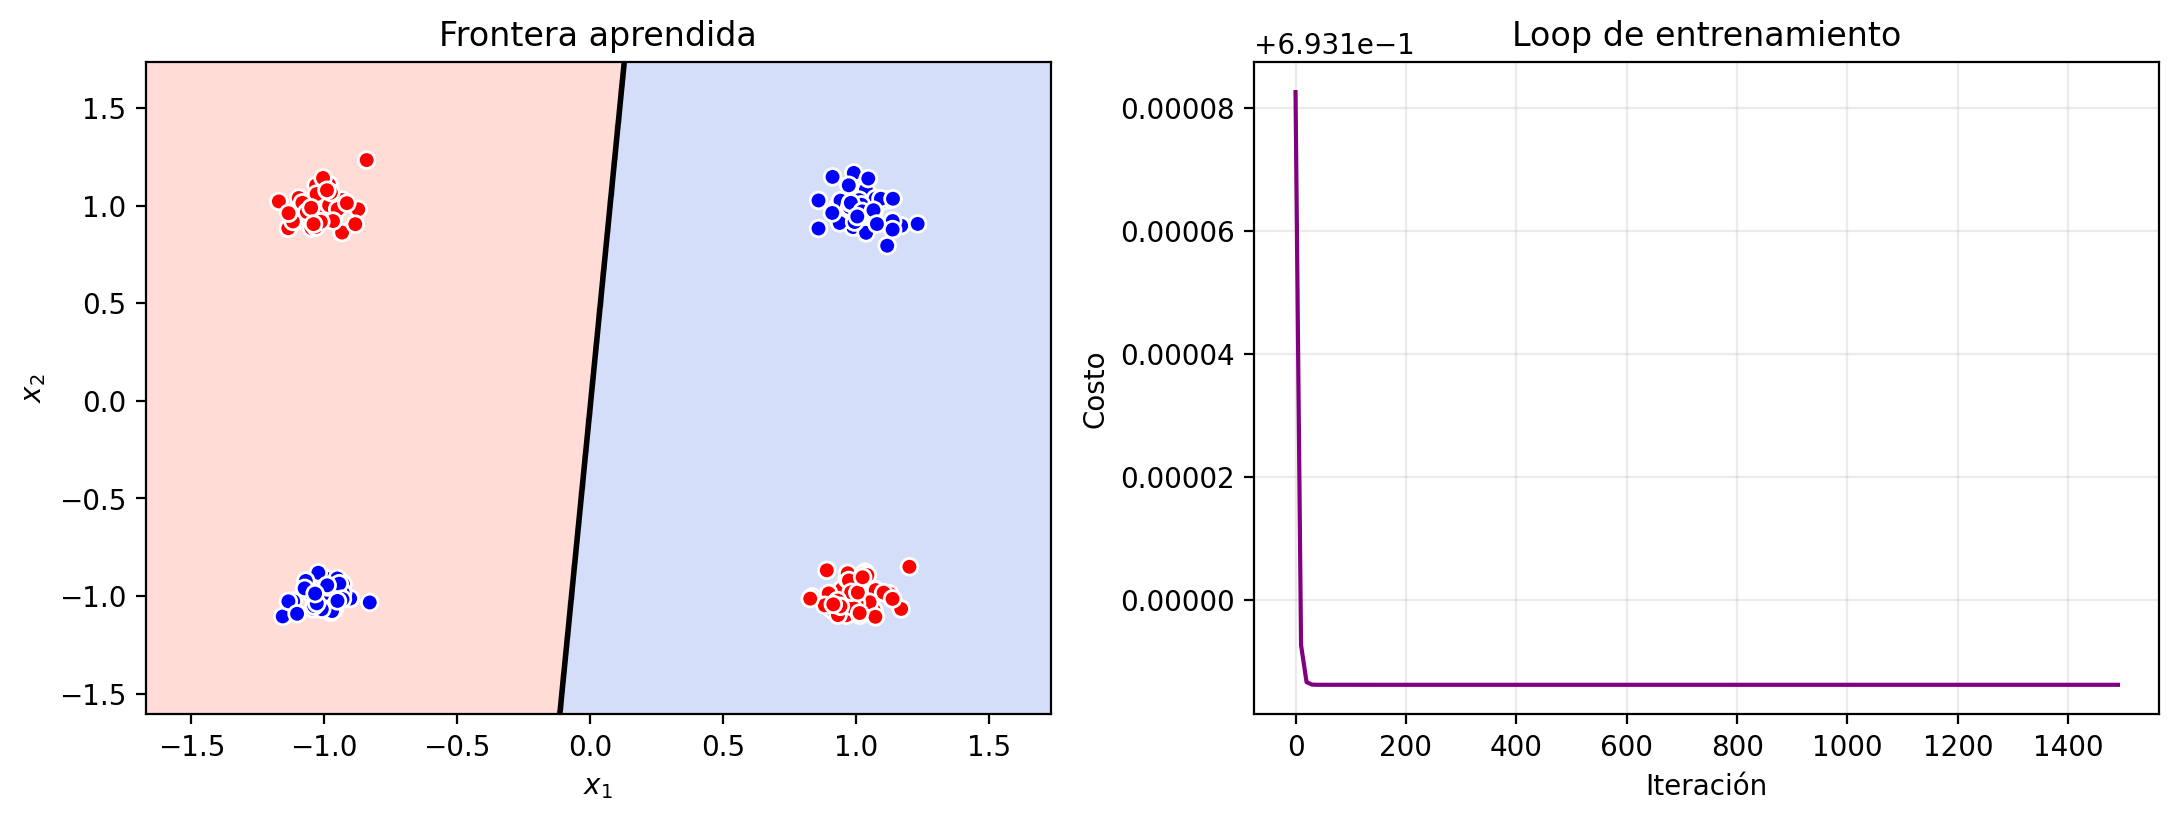

In [ ]:
x1_min, x1_max = X[0].min() - 0.5, X[0].max() + 0.5
x2_min, x2_max = X[1].min() - 0.5, X[1].max() + 0.5
eje_x1 = np.linspace(x1_min, x1_max, 250)
eje_x2 = np.linspace(x2_min, x2_max, 250)
malla_x1, malla_x2 = np.meshgrid(eje_x1, eje_x2)
puntos_malla = np.vstack((malla_x1.ravel(), malla_x2.ravel()))
Z_malla = parameters["W"] @ puntos_malla + parameters["b"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].contourf(
    malla_x1,
    malla_x2,
    (Z_malla.reshape(malla_x1.shape) > 0).astype(int),
    alpha=0.22,
    cmap=ListedColormap(["royalblue", "tomato"]),
)
axes[0].contour(
    malla_x1,
    malla_x2,
    Z_malla.reshape(malla_x1.shape),
    levels=[0],
    colors="black",
    linewidths=2,
)
axes[0].scatter(
    X[0], X[1], c=y.ravel(),
    cmap=ListedColormap(["blue", "red"]), edgecolor="white",
)
axes[0].set(title="Frontera aprendida", xlabel="$x_1$", ylabel="$x_2$")

pasos, valores_cost = zip(*costs)
axes[1].plot(pasos, valores_cost, color="purple")
axes[1].set(title="Loop de entrenamiento", xlabel="Iteración", ylabel="Costo")
axes[1].grid(alpha=0.25)
fig.tight_layout()

fig

In [ ]:
interpretacion = (
    "En este caso una recta es suficiente para separar las clases."
    if conjunto.value == "lineal"
    else "Aunque el costo disminuya, una sola recta no puede representar la geometría completa del problema."
)
mo.callout(
    mo.md(
        rf"""
        **Exactitud obtenida: {accuracy:.1%}**

        {interpretacion}

        La limitación no se debe necesariamente al número de iteraciones. Se
        debe a la estructura del modelo: la frontera \(WX+b=0\) siempre es una
        recta. Esto motiva la incorporación de una **capa oculta con varias
        neuronas**.
        """
    ),
    kind="info",
)

<marimo-callout-output data-html='"\u003cspan class=\"markdown prose dark:prose-invert contents\"\u003e\u003cspan class=\"paragraph\"\u003e\u003cstrong\u003eExactitud obtenida: 50.0%\u003c/strong\u003e\u003c/span\u003e\n\u003cspan class=\"paragraph\"\u003eAunque el costo disminuya, una sola recta no puede representar la geometría completa del problema.\u003c/span\u003e\n\u003cspan class=\"paragraph\"\u003eLa limitación no se debe necesariamente al número de iteraciones. Se\ndebe a la estructura del modelo: la frontera \u003cmarimo-tex class=\"arithmatex\"\u003e||(WX+b=0||)\u003c/marimo-tex\u003e siempre es una\nrecta. Esto motiva la incorporación de una \u003cstrong\u003ecapa oculta con varias\nneuronas\u003c/strong\u003e.\u003c/span\u003e\u003c/span\u003e"' data-kind='"info"'>

## Preguntas sobre el tema

1. Selecciona los tres conjuntos y compara la exactitud.
2. Aumenta el número de iteraciones en XOR. ¿Desaparece la limitación?
3. Cambia el *learning rate*. ¿Qué parte del resultado corresponde a la
   optimización y qué parte corresponde a la capacidad del modelo?
4. Explica por qué agregar más variables de entrada no resolvería por sí solo
   el problema XOR.

## Respuestas

Los controles de arriba sirven para explorar, pero para responder quería comparar todo con
las mismas condiciones. Así que en las celdas de abajo uso las mismas funciones del notebook
(`construir_datos`, `nn_model` y `forward_propagation`) y corro los experimentos con valores
fijos: ruido 0.08, 1500 iteraciones, learning rate 0.5 y semilla 42, salvo cuando cambio uno
de ellos a propósito.

In [ ]:
def tabla_md(filas):
    """
    Argumentos:
    filas -- lista de diccionarios (una fila por diccionario)

    Retorna:
    texto de una tabla en markdown, para que se vea igual en marimo, Jupyter y GitHub
    """
    columnas = list(filas[0].keys())
    lineas = ["| " + " | ".join(columnas) + " |", "|" + "---|" * len(columnas)]
    for f in filas:
        lineas.append("| " + " | ".join(str(f[c]) for c in columnas) + " |")
    return "\n".join(lineas)

In [ ]:
def experimento(nombre, ruido=0.08, iteraciones=1500, learning_rate=0.5, X=None, y=None):
    """
    Entrena una neurona con los datos indicados y regresa exactitud, costo final y parámetros.
    Si se pasan X e y, se usan esos datos en lugar de construirlos.
    """
    if X is None:
        X, y = construir_datos(nombre, ruido)
    parametros, costos = nn_model(X, y, iterations=iteraciones, learning_rate=learning_rate)
    prob = forward_propagation(X, parametros)
    exactitud = float(np.mean((prob > 0.5).astype(int) == y))
    return {"exactitud": exactitud, "costo": float(costos[-1][1]), "parametros": parametros}

### 1. Comparación de los tres conjuntos

In [ ]:
nombres = {"lineal": "Dos grupos separables", "xor": "Compuerta XOR", "lunas": "Dos lunas"}
resultados_base = {n: experimento(n) for n in nombres}
mo.md(tabla_md([
    {"Conjunto": nombres[n],
     "Exactitud": f"{r['exactitud']:.1%}",
     "Costo final": f"{r['costo']:.4f}",
     "w1": f"{r['parametros']['W'][0, 0]:.3f}",
     "w2": f"{r['parametros']['W'][0, 1]:.3f}"}
    for n, r in resultados_base.items()
]))

| Conjunto | Exactitud | Costo final | w1 | w2 |
|---|---|---|---|---|
| Dos grupos separables | 100.0% | 0.0013 | 4.105 | 3.225 |
| Compuerta XOR | 50.0% | 0.6931 | -0.022 | 0.002 |
| Dos lunas | 86.5% | 0.2655 | 1.147 | -5.485 |

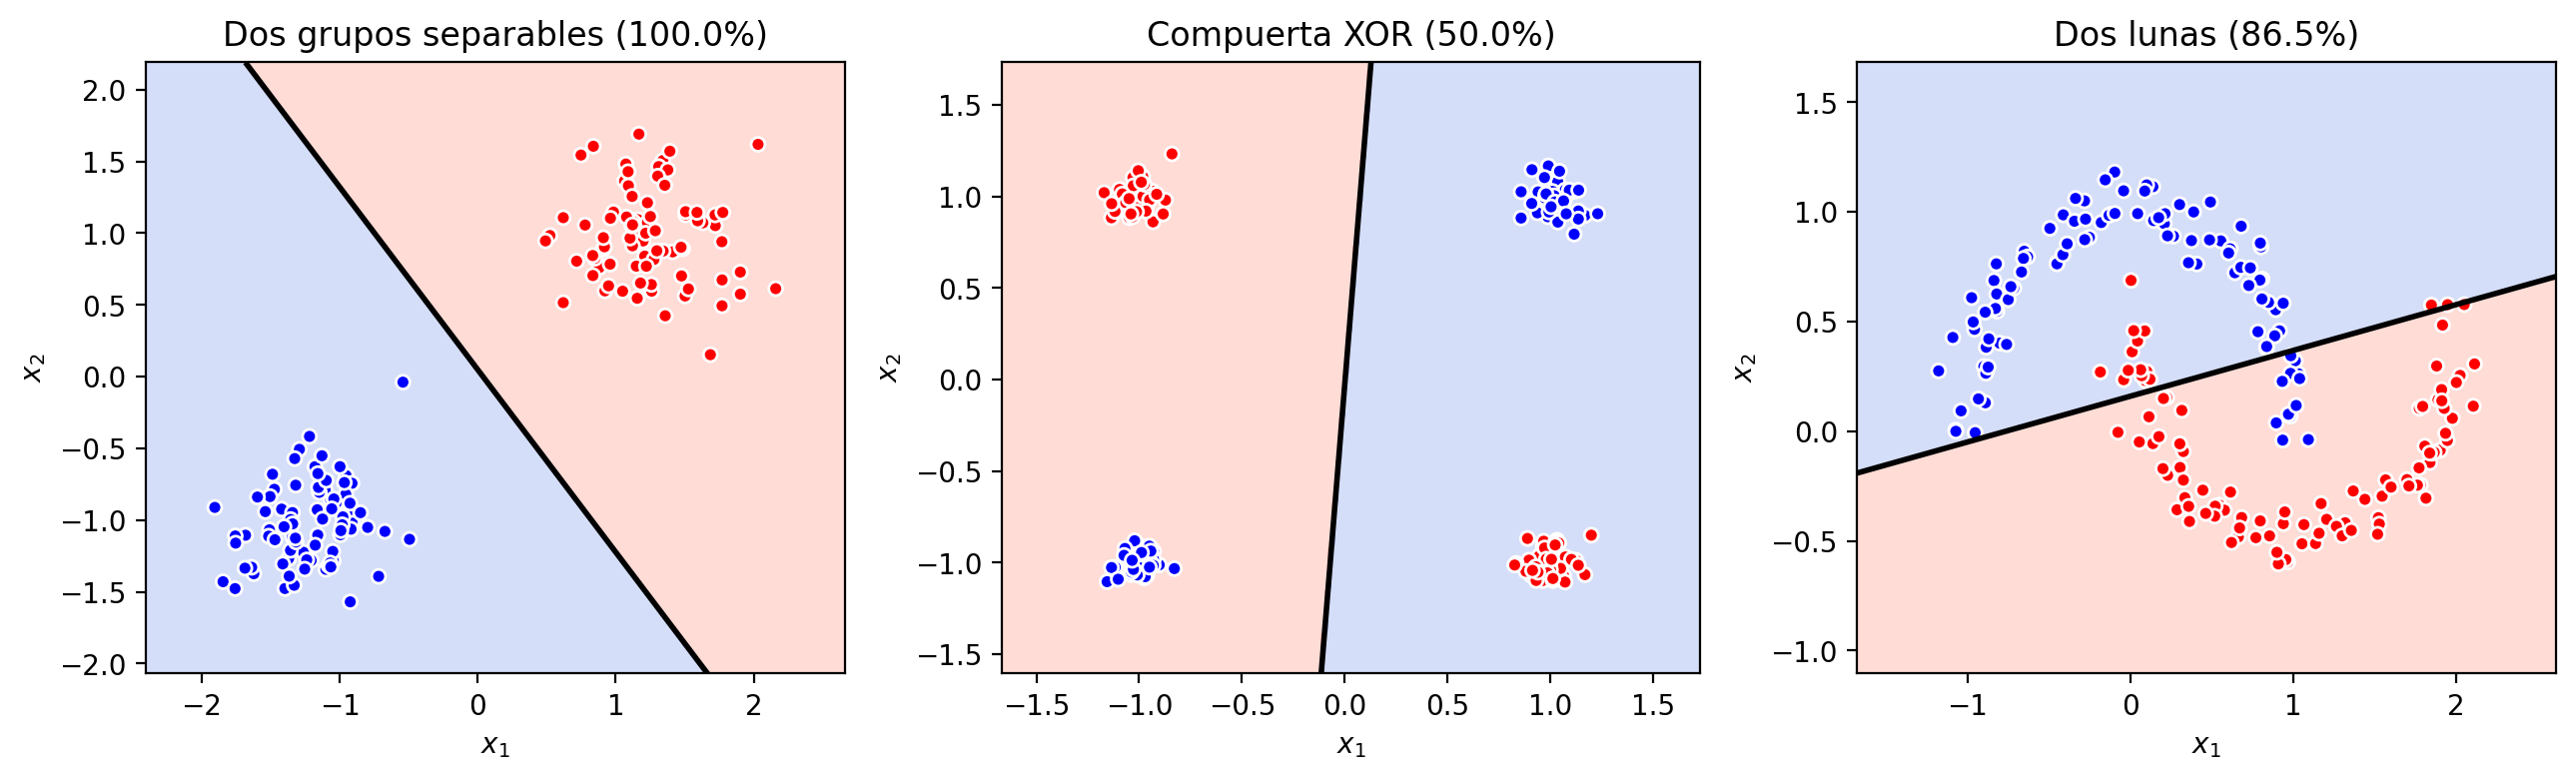

In [ ]:
fig_tres, ax_tres = plt.subplots(1, 3, figsize=(13, 4))
for _ax, _n in zip(ax_tres, nombres):
    _X, _y = construir_datos(_n, 0.08)
    _p = resultados_base[_n]["parametros"]
    _g1, _g2 = np.meshgrid(np.linspace(_X[0].min() - 0.5, _X[0].max() + 0.5, 200),
                           np.linspace(_X[1].min() - 0.5, _X[1].max() + 0.5, 200))
    _Z = (_p["W"] @ np.vstack((_g1.ravel(), _g2.ravel())) + _p["b"]).reshape(_g1.shape)
    _ax.contourf(_g1, _g2, (_Z > 0).astype(int), alpha=0.22,
                 cmap=ListedColormap(["royalblue", "tomato"]))
    _ax.contour(_g1, _g2, _Z, levels=[0], colors="black", linewidths=2)
    _ax.scatter(_X[0], _X[1], c=_y.ravel(), cmap=ListedColormap(["blue", "red"]),
                edgecolor="white", s=25)
    _ax.set(title=f"{nombres[_n]} ({resultados_base[_n]['exactitud']:.1%})",
            xlabel="$x_1$", ylabel="$x_2$")
fig_tres.tight_layout()
fig_tres

In [ ]:
_x = resultados_base["xor"]
mo.md(rf"""
Con los grupos separables la neurona llega a {resultados_base["lineal"]["exactitud"]:.0%}, porque
basta una recta para dividirlos. Con las dos lunas se queda en
{resultados_base["lunas"]["exactitud"]:.1%}: la recta separa la mayor parte, pero las puntas
de cada luna se meten del lado contrario y esas siempre las clasifica mal.

El caso de XOR es el más claro. La exactitud es de {_x["exactitud"]:.0%}, lo mismo que adivinar
al azar, y el costo se queda en {_x["costo"]:.4f}, que es $\ln 2$. Ese número no es casualidad:
es la entropía cruzada que se obtiene cuando el modelo predice 0.5 para todo. Los pesos se
quedan prácticamente en su valor inicial ($w_1 \approx$ {_x["parametros"]["W"][0, 0]:.3f},
$w_2 \approx$ {_x["parametros"]["W"][0, 1]:.3f}). Como XOR es simétrico, cualquier recta que
deje de un lado más puntos rojos también deja la misma cantidad de azules, así que el
gradiente se cancela y la neurona no tiene hacia dónde moverse. La mejor "recta" que encuentra
es no decidir nada.
""")

Con los grupos separables la neurona llega a 100%, porque
basta una recta para dividirlos. Con las dos lunas se queda en
86.5%: la recta separa la mayor parte, pero las puntas
de cada luna se meten del lado contrario y esas siempre las clasifica mal.

El caso de XOR es el más claro. La exactitud es de 50%, lo mismo que adivinar
al azar, y el costo se queda en 0.6931, que es $\ln 2$. Ese número no es casualidad:
es la entropía cruzada que se obtiene cuando el modelo predice 0.5 para todo. Los pesos se
quedan prácticamente en su valor inicial ($w_1 \approx$ -0.022,
$w_2 \approx$ 0.002). Como XOR es simétrico, cualquier recta que
deje de un lado más puntos rojos también deja la misma cantidad de azules, así que el
gradiente se cancela y la neurona no tiene hacia dónde moverse. La mejor "recta" que encuentra
es no decidir nada.

### 2. Más iteraciones en XOR

In [ ]:
filas_it = []
for _it in [100, 500, 1500, 5000, 20000]:
    _r = experimento("xor", iteraciones=_it)
    filas_it.append({"Iteraciones": _it, "Exactitud": f"{_r['exactitud']:.1%}",
                     "Costo final": f"{_r['costo']:.4f}"})
mo.md(tabla_md(filas_it))

| Iteraciones | Exactitud | Costo final |
|---|---|---|
| 100 | 50.0% | 0.6931 |
| 500 | 50.0% | 0.6931 |
| 1500 | 50.0% | 0.6931 |
| 5000 | 50.0% | 0.6931 |
| 20000 | 50.0% | 0.6931 |

No, la limitación no desaparece. Probé desde 100 hasta 20,000 iteraciones y la exactitud se
queda en 50 % con el costo clavado en 0.6931 en todos los casos. Entrenar más tiempo sirve
cuando el modelo todavía no llega a su mejor solución, pero aquí ya llegó desde el principio:
la mejor frontera lineal posible para XOR sigue clasificando mal a la mitad de los puntos.

### 3. Cambiar el learning rate

In [ ]:
filas_lr = []
for _lr in [0.01, 0.1, 0.5, 1.0, 2.0]:
    _fila = {"Learning rate": _lr}
    for _n in nombres:
        _r = experimento(_n, learning_rate=_lr)
        _fila[f"{nombres[_n]} (exactitud / costo)"] = f"{_r['exactitud']:.1%} / {_r['costo']:.4f}"
    filas_lr.append(_fila)
mo.md(tabla_md(filas_lr))

| Learning rate | Dos grupos separables (exactitud / costo) | Compuerta XOR (exactitud / costo) | Dos lunas (exactitud / costo) |
|---|---|---|---|
| 0.01 | 100.0% / 0.0355 | 50.0% / 0.6931 | 82.5% / 0.3602 |
| 0.1 | 100.0% / 0.0046 | 50.0% / 0.6931 | 87.5% / 0.2697 |
| 0.5 | 100.0% / 0.0013 | 50.0% / 0.6931 | 86.5% / 0.2655 |
| 1.0 | 100.0% / 0.0007 | 50.0% / 0.6931 | 86.5% / 0.2655 |
| 2.0 | 100.0% / 0.0004 | 50.0% / 0.6931 | 86.5% / 0.2655 |

El learning rate cambia la **optimización**, es decir, qué tan rápido y qué tan cerca llega la
neurona a su mejor solución. En los grupos separables se nota en el costo: con 0.01 termina en
0.0355 y con 2.0 baja hasta 0.0004, aunque la exactitud es 100 % en todos los casos. En las
lunas, con 0.01 no le alcanzan las 1500 iteraciones y se queda en 82.5 %; de 0.5 en adelante ya
se estabiliza en 86.5 %.

Lo que el learning rate no cambia es la **capacidad** del modelo, que es el techo al que puede
llegar. Ese techo lo pone la forma de la frontera: con una sola neurona siempre es una recta.
Por eso en XOR da igual el valor que use, siempre termina en 50 %, y en las lunas la
exactitud se queda entre 82.5 % y 87.5 % por más que mueva la tasa. (Con 0.1 sale 87.5 %, un
poco más que con 0.5, aunque su costo es mayor; con tan pocos puntos, un par de puntos de
la orilla cambian de lado y eso mueve la exactitud sin que el modelo sea mejor.) Si con todos
los valores el resultado se estanca en el mismo rango, el problema ya no es de optimización
sino del modelo.

### 4. ¿Agregar variables resolvería XOR?

Para responder probé agregarle a XOR distintas variables de entrada, siempre con la misma
neurona.

In [ ]:
_X, _y = construir_datos("xor", 0.08)
_ruido = np.random.default_rng(0).normal(0, 1, (1, _X.shape[1]))
variantes = {
    "Solo x1, x2 (original)": _X,
    "x1, x2 + una variable de ruido": np.vstack([_X, _ruido]),
    "x1, x2 + (x1 + x2)": np.vstack([_X, _X[0] + _X[1]]),
    "x1, x2 + x1² + x2²": np.vstack([_X, _X[0] ** 2, _X[1] ** 2]),
    "x1, x2 + x1·x2": np.vstack([_X, _X[0] * _X[1]]),
}
filas_var = []
for _nombre, _Xv in variantes.items():
    _r = experimento("xor", X=_Xv, y=_y)
    filas_var.append({"Entradas": _nombre, "Variables": _Xv.shape[0],
                      "Exactitud": f"{_r['exactitud']:.1%}", "Costo final": f"{_r['costo']:.4f}"})
mo.md(tabla_md(filas_var))

| Entradas | Variables | Exactitud | Costo final |
|---|---|---|---|
| Solo x1, x2 (original) | 2 | 50.0% | 0.6931 |
| x1, x2 + una variable de ruido | 3 | 53.8% | 0.6835 |
| x1, x2 + (x1 + x2) | 3 | 50.0% | 0.6931 |
| x1, x2 + x1² + x2² | 4 | 50.0% | 0.6921 |
| x1, x2 + x1·x2 | 3 | 100.0% | 0.0015 |

Agregar variables por sí solo no lo resuelve, y la tabla lo muestra. Con una variable de ruido
la exactitud apenas se mueve a 53.8 %, y eso es porque la neurona se ajusta un poco al ruido de
estos 160 puntos, no porque entienda el problema. Con $x_1 + x_2$ no cambia nada, porque es una
combinación lineal de lo que ya tenía: la frontera $WX + b = 0$ sigue siendo un plano y ese
plano, visto en el espacio de $x_1$ y $x_2$, vuelve a ser una recta. Con $x_1^2$ y $x_2^2$
tampoco, porque en XOR todos los puntos están en $\pm 1$ y al elevarlos al cuadrado quedan
todos cerca de 1, así que esas variables no distinguen una clase de otra.

Lo que sí funciona es agregar $x_1 \cdot x_2$: la exactitud sube a 100 %. Pero ahí ya no es
"una variable más", sino una transformación no lineal que yo elegí sabiendo cómo es XOR (el
producto es positivo en una clase y negativo en la otra). En problemas reales no sabemos de
antemano qué transformación sirve. Eso es justo lo que hace una **capa oculta**: cada neurona
oculta genera su propia combinación no lineal de las entradas, y la neurona de salida separa
con una recta en ese nuevo espacio. O sea, la red aprende sola las variables que aquí tuve que
inventar a mano.

### Conclusión

Con una sola neurona la frontera de decisión siempre es una recta, y eso no lo arreglan ni más
iteraciones, ni otro learning rate, ni más variables lineales. Cuando las clases no se pueden
separar con una recta, como en XOR o en las lunas, hace falta cambiar el modelo y agregar una
capa oculta, que es el siguiente tema.